Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 61s 33ms/step - accuracy: 0.9533 - loss: 0.1559 - val_accuracy: 0.9853 - val_loss: 0.0512
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9843 - loss: 0.0505 - val_accuracy: 0.9860 - val_loss: 0.0432
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 49s 29ms/step - accuracy: 0.9898 - loss: 0.0335 - val_accuracy: 0.9888 - val_loss: 0.0443
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 84s 30ms/step - accuracy: 0.9932 - loss: 0.0223 - val_accuracy: 0.9887 - val_loss: 0.0472
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 84s 31ms/step - accuracy: 0.9948 - loss: 0.0173 - val_accuracy: 0.9877 - val_loss: 0.0520
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9874 - loss: 0.0419
Test Accuracy: 0.9873999953269958
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step
Predicted Digit: 7
Actual Digit: 7


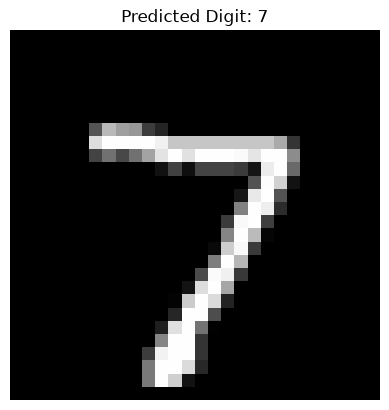

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize and reshape input data
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Build the CNN model architecture
model = models.Sequential([
    # Input layer
    layers.Input(shape=(28, 28, 1)),
    
    # Convolution Layer
    layers.Conv2D(32, (3, 3), activation='relu'),
    
    # Pooling Layer
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolution Layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    
    # Second Pooling Layer
    layers.MaxPooling2D((2, 2)),
    
    # Convert 2D feature maps into 1D
    layers.Flatten(),
    
    # Fully Connected Layer
    layers.Dense(64, activation='relu'),
    
    # Output Layer
    layers.Dense(10, activation='softmax')
])

model.summary()

# 5.compile model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# 6. Train the Model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)


# 7. Test the Model

test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)


# 8. Predict a Digit

prediction = model.predict(x_test)
digit = prediction[0].argmax()

print("Predicted Digit:", digit)
print("Actual Digit:", y_test[0])


# 9. Display Image

plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.title("Predicted Digit: " + str(digit))
plt.axis('off')
plt.show()